✅ Against All Odds — Week 8: Logistic Regression
Project root: /content/againstallodds

Missing Week 6 model-ready files:
 - nba_model_ready_2021_22_to_2025_26.csv
 - nfl_model_ready_2021_to_2025.csv
 - premier_league_model_ready_2021_22_to_2025_26.csv

Upload the missing CSVs or a ZIP containing them.


Saving New folder.zip to New folder.zip

✅ Model-ready inputs located:
 - NBA: /content/week8_inputs/New folder/nba_model_ready_2021_22_to_2025_26.csv
 - NFL: /content/week8_inputs/New folder/nfl_model_ready_2021_to_2025.csv
 - Premier League: /content/week8_inputs/New folder/premier_league_model_ready_2021_22_to_2025_26.csv
NBA | rows = 6061 | splits = ['TEST', 'TRAIN', 'VALIDATION']
NFL | rows = 1276 | splits = ['TEST', 'TRAIN', 'VALIDATION']
Premier League | rows = 1850 | splits = ['TEST', 'TRAIN', 'VALIDATION']


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


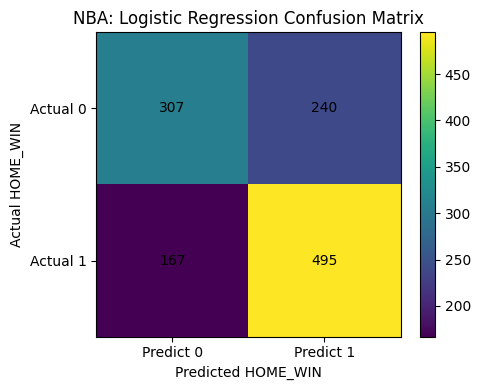

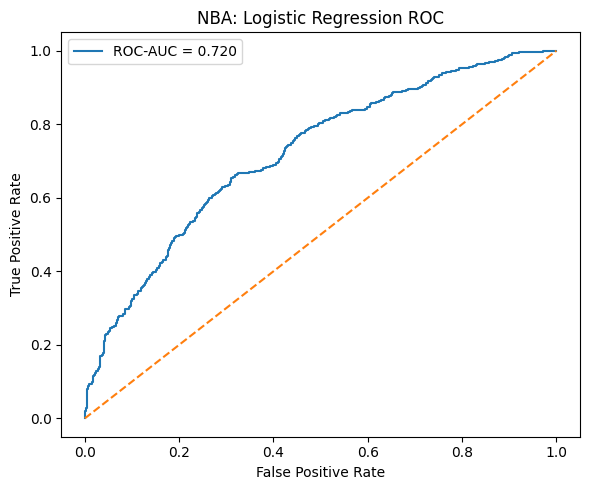

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


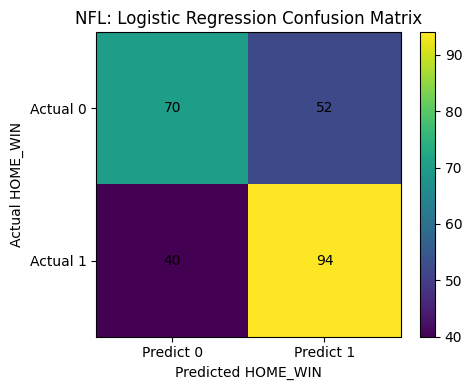

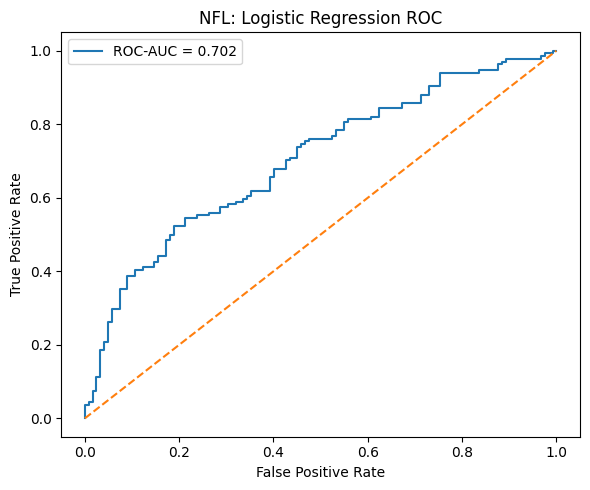

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


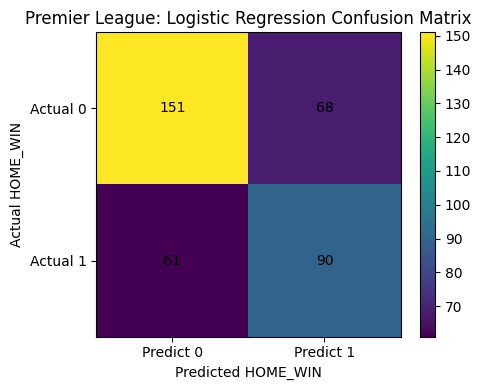

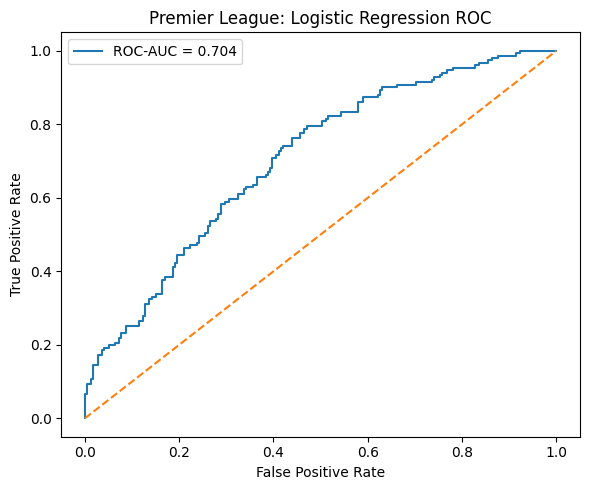


Validation metrics:


,sport,model,data_split,games,accuracy,precision,recall,f1,roc_auc,brier_score,log_loss,true_negative,false_positive,false_negative,true_positive
0,NBA,Logistic Regression,VALIDATION,1209,0.663358,0.673469,0.747734,0.708661,0.720033,0.211450,0.609445,307,240,167,495
1,NFL,Logistic Regression,VALIDATION,256,0.640625,0.643836,0.701493,0.671429,0.701676,0.219972,0.629782,70,52,40,94
2,Premier League,Logistic Regression,VALIDATION,370,0.651351,0.569620,0.596026,0.582524,0.704225,0.215326,0.616042,151,68,61,90



Coefficients / odds ratios / significance:


,sport,feature,coefficient,odds_ratio,p_value,ci_lower_coefficient,ci_upper_coefficient,ci_lower_odds_ratio,ci_upper_odds_ratio,statistically_significant_0_05
0,NBA,const,0.244847,1.277426,5.555825e-12,0.175203,0.314491,1.191488,1.369563,True
1,NBA,ELO_DIFF,0.004392,1.004402,6.078231e-20,0.003451,0.005334,1.003457,1.005348,True
2,NBA,WIN_PCT_DIFF,-0.419448,0.657409,2.320329e-01,-1.107321,0.268425,0.330443,1.307903,False
3,NBA,FORM_DIFF,-0.080675,0.922493,5.400933e-01,-0.338759,0.177409,0.712654,1.194119,False
4,NBA,POINT_GOAL_DIFF,0.025314,1.025637,2.561089e-04,0.011743,0.038884,1.011813,1.039650,True
5,NBA,OFFENSE_DIFF,0.012115,1.012189,1.667528e-02,0.002196,0.022034,1.002198,1.022279,True
6,NBA,DEFENSE_DIFF,0.013199,1.013286,5.592769e-03,0.003862,0.022535,1.003870,1.022791,True
7,NBA,REST_DIFF,0.133824,1.143192,1.220702e-04,0.065554,0.202095,1.067750,1.223964,True
8,NBA,SCHEDULE_STRENGTH_DIFF,0.000730,1.000731,2.424352e-01,-0.000494,0.001955,0.999506,1.001957,False
9,NFL,const,0.222713,1.249462,3.347278e-03,0.073932,0.371495,1.076734,1.449900,True



✅ Logistic results saved


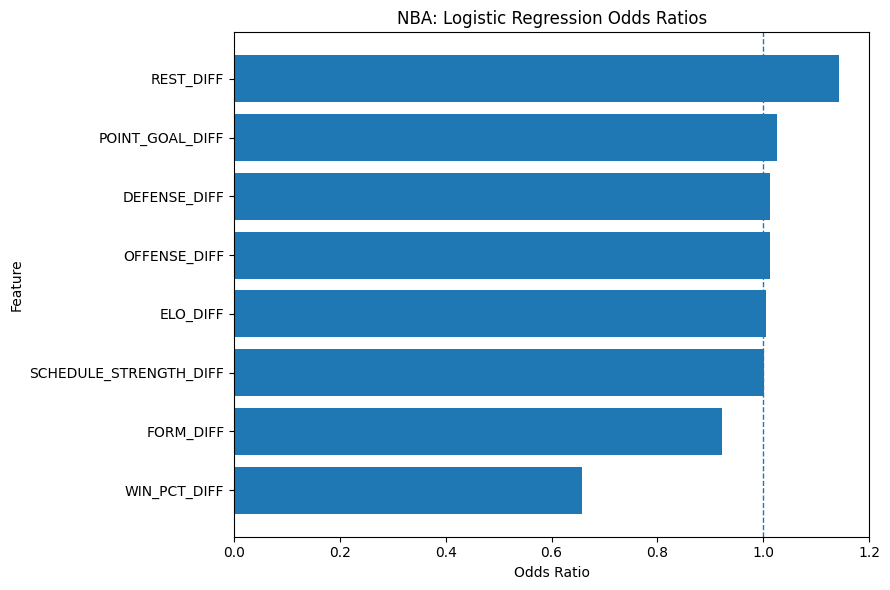

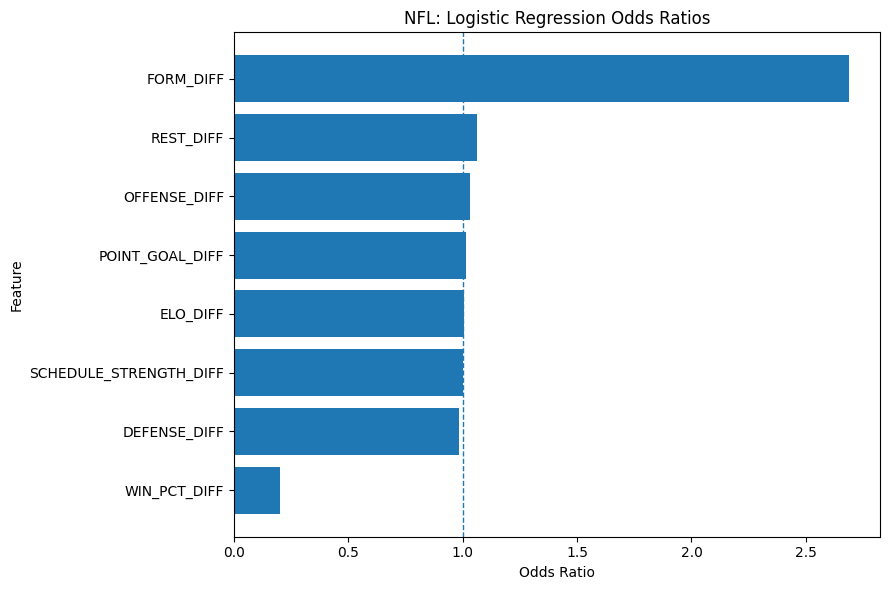

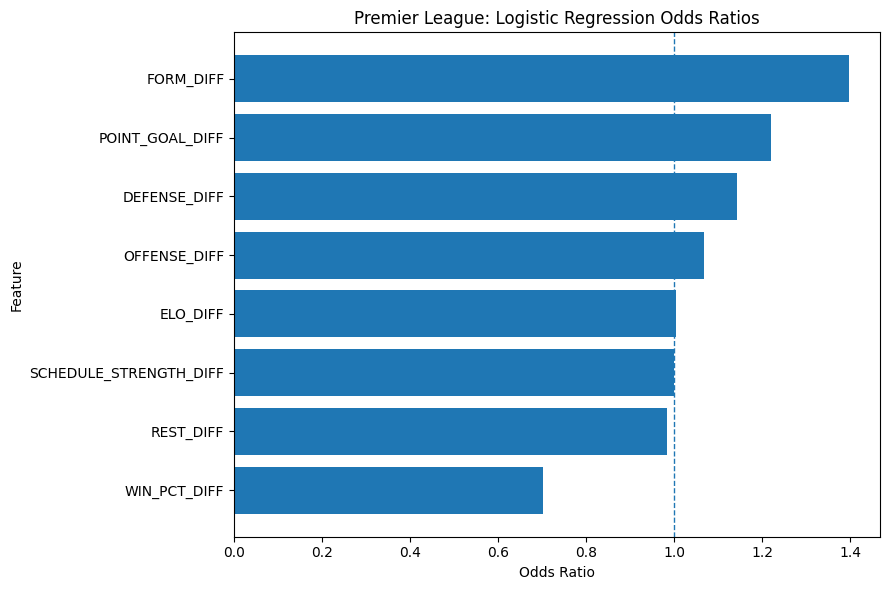

,check,passed
0,three_sports_modeled,True
1,three_validation_metric_rows,True
2,coefficients_created,True
3,validation_probabilities_valid,True
4,test_held_out_by_default,True



AGAINST ALL ODDS — WEEK 8 LOGISTIC REGRESSION COMPLETE
✅ NBA logistic regression
✅ NFL logistic regression
✅ Premier League logistic regression
✅ Coefficients
✅ Odds ratios
✅ Statistical significance
✅ Predicted probabilities
✅ TEST split held out

Next: run 10_elo_model.ipynb


In [1]:

# ============================================================
# AGAINST ALL ODDS — WEEK 8A: LOGISTIC REGRESSION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import sys
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    brier_score_loss,
    log_loss,
    roc_curve,
)

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_TITLE = "Against All Odds"
WEEK_NUMBER = 8
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Keep the final test split untouched during Week 8.
USE_TEST_SPLIT = False

# Shared leakage-safe feature set created in Week 6.
CORE_FEATURES = [
    "ELO_DIFF",
    "WIN_PCT_DIFF",
    "FORM_DIFF",
    "POINT_GOAL_DIFF",
    "OFFENSE_DIFF",
    "DEFENSE_DIFF",
    "REST_DIFF",
    "SCHEDULE_STRENGTH_DIFF",
]

EXPECTED_INPUTS = {
    "NBA": "nba_model_ready_2021_22_to_2025_26.csv",
    "NFL": "nfl_model_ready_2021_to_2025.csv",
    "Premier League": "premier_league_model_ready_2021_22_to_2025_26.csv",
}


def running_in_colab():
    return "google.colab" in sys.modules


def choose_project_root():
    cwd = Path.cwd().resolve()

    candidates = [
        cwd if cwd.name.lower().replace("_", "-") in {
            "againstallodds",
            "against-all-odds",
        } else None,
        Path("/content/againstallodds"),
        Path("/content/Against-All-Odds"),
        Path("/content/drive/MyDrive/againstallodds"),
        Path("/content/drive/MyDrive/Against-All-Odds"),
    ]

    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return candidate

    if running_in_colab():
        return Path("/content/againstallodds")

    return cwd / "againstallodds"


PROJECT_ROOT = choose_project_root()
MODEL_READY_DIR = PROJECT_ROOT / "data" / "model_ready"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures" / "week8"
DOCS_DIR = PROJECT_ROOT / "docs"

for folder in [MODEL_READY_DIR, RESULTS_DIR, FIGURES_DIR, DOCS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"✅ {PROJECT_TITLE} — Week {WEEK_NUMBER}: Logistic Regression")
print("Project root:", PROJECT_ROOT)


def search_locations():
    locations = [
        PROJECT_ROOT,
        MODEL_READY_DIR,
        Path("/content"),
        Path("/content/week8_inputs"),
        Path.cwd().resolve(),
    ]

    for extra in [
        Path("/content/drive/MyDrive/againstallodds"),
        Path("/content/drive/MyDrive/Against-All-Odds"),
    ]:
        if extra.exists():
            locations.append(extra)

    return list(dict.fromkeys([p for p in locations if p.exists()]))


def find_exact_file(filename):
    for root in search_locations():
        direct = root / filename
        if direct.exists():
            return direct

    for root in search_locations():
        try:
            matches = list(root.rglob(filename))
        except (PermissionError, OSError):
            matches = []

        if matches:
            return matches[0]

    return None


def resolve_inputs():
    found = {
        sport: find_exact_file(filename)
        for sport, filename in EXPECTED_INPUTS.items()
    }

    missing = [
        filename
        for sport, filename in EXPECTED_INPUTS.items()
        if found[sport] is None
    ]

    if missing and running_in_colab():
        print("\nMissing Week 6 model-ready files:")
        for name in missing:
            print(" -", name)

        print("\nUpload the missing CSVs or a ZIP containing them.")

        from google.colab import files

        uploaded = files.upload()
        upload_dir = Path("/content/week8_inputs")
        upload_dir.mkdir(parents=True, exist_ok=True)

        for name, blob in uploaded.items():
            destination = upload_dir / Path(name).name
            destination.write_bytes(blob)

            if zipfile.is_zipfile(destination):
                with zipfile.ZipFile(destination, "r") as archive:
                    archive.extractall(upload_dir)

        found = {
            sport: find_exact_file(filename)
            for sport, filename in EXPECTED_INPUTS.items()
        }

    still_missing = [
        EXPECTED_INPUTS[sport]
        for sport, path in found.items()
        if path is None
    ]

    if still_missing:
        raise FileNotFoundError(
            "Week 8 logistic regression cannot start because these files are missing:\n"
            + "\n".join(f" - {name}" for name in still_missing)
            + "\n\nRun Week 6 first, then rerun this cell."
        )

    return found


INPUT_PATHS = resolve_inputs()

print("\n✅ Model-ready inputs located:")
for sport, path in INPUT_PATHS.items():
    print(f" - {sport}: {path}")


# ============================================================
# LOAD AND VALIDATE DATA
# ============================================================

datasets = {}

for sport, path in INPUT_PATHS.items():
    df = pd.read_csv(
        path,
        dtype={"game_id": "string"},
        parse_dates=["game_date"],
    )

    df["data_split"] = (
        df["data_split"]
        .astype("string")
        .str.upper()
        .str.strip()
    )

    df["HOME_WIN"] = pd.to_numeric(
        df["HOME_WIN"],
        errors="coerce",
    )

    required = (
        ["game_id", "game_date", "data_split", "HOME_WIN"]
        + CORE_FEATURES
    )

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{sport} is missing required columns: {missing}"
        )

    for feature in CORE_FEATURES:
        df[feature] = pd.to_numeric(
            df[feature],
            errors="coerce",
        )

    df = (
        df
        .dropna(
            subset=CORE_FEATURES + ["HOME_WIN"]
        )
        .sort_values(
            ["game_date", "game_id"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    if not df["HOME_WIN"].isin([0, 1]).all():
        raise ValueError(
            f"{sport}: HOME_WIN must be binary."
        )

    datasets[sport] = df

    print(
        sport,
        "| rows =", len(df),
        "| splits =", sorted(df["data_split"].unique().tolist()),
    )


# ============================================================
# HELPERS
# ============================================================

def evaluate_probabilities(y_true, probability):
    probability = np.clip(
        np.asarray(probability, dtype=float),
        1e-6,
        1 - 1e-6,
    )

    prediction = (
        probability >= 0.50
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1],
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            prediction,
        ),
        "precision": precision_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probability,
        ),
        "brier_score": brier_score_loss(
            y_true,
            probability,
        ),
        "log_loss": log_loss(
            y_true,
            probability,
            labels=[0, 1],
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


def save_confusion_matrix(
    y_true,
    probability,
    sport,
):
    prediction = (
        np.asarray(probability) >= 0.50
    ).astype(int)

    matrix = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1],
    )

    fig, ax = plt.subplots(
        figsize=(5, 4)
    )

    image = ax.imshow(matrix)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(
        ["Predict 0", "Predict 1"]
    )
    ax.set_yticklabels(
        ["Actual 0", "Actual 1"]
    )
    ax.set_xlabel("Predicted HOME_WIN")
    ax.set_ylabel("Actual HOME_WIN")
    ax.set_title(
        f"{sport}: Logistic Regression Confusion Matrix"
    )

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(matrix[i, j]),
                ha="center",
                va="center",
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        FIGURES_DIR
        / f"week8_{safe_sport}_logistic_confusion_validation.png"
    )

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    return path


def save_roc_curve(
    y_true,
    probability,
    sport,
):
    fpr, tpr, _ = roc_curve(
        y_true,
        probability,
    )

    auc_value = roc_auc_score(
        y_true,
        probability,
    )

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    ax.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {auc_value:.3f}",
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(
        f"{sport}: Logistic Regression ROC"
    )
    ax.legend()
    fig.tight_layout()

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        FIGURES_DIR
        / f"week8_{safe_sport}_logistic_roc_validation.png"
    )

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    return path


# ============================================================
# TRAIN SEPARATE MODELS FOR NBA, NFL, PREMIER LEAGUE
# ============================================================

fitted_models = {}
metrics_rows = []
coefficient_frames = []
prediction_paths = []
figure_paths = []

for sport, df in datasets.items():
    train = df[
        df["data_split"].eq("TRAIN")
    ].copy()

    validation = df[
        df["data_split"].eq("VALIDATION")
    ].copy()

    test = df[
        df["data_split"].eq("TEST")
    ].copy()

    if train.empty:
        raise ValueError(
            f"{sport}: TRAIN split is empty."
        )

    if validation.empty:
        raise ValueError(
            f"{sport}: VALIDATION split is empty."
        )

    X_train = train[
        CORE_FEATURES
    ].copy()

    y_train = train[
        "HOME_WIN"
    ].astype(int)

    X_validation = validation[
        CORE_FEATURES
    ].copy()

    y_validation = validation[
        "HOME_WIN"
    ].astype(int)

    # Predictive model:
    # Standardize predictors before fitting logistic regression.
    predictive_model = Pipeline([
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=5000,
                random_state=RANDOM_SEED,
            ),
        ),
    ])

    predictive_model.fit(
        X_train,
        y_train,
    )

    validation_probability = (
        predictive_model
        .predict_proba(
            X_validation
        )[:, 1]
    )

    validation_metrics = evaluate_probabilities(
        y_validation,
        validation_probability,
    )

    metrics_rows.append({
        "sport": sport,
        "model": "Logistic Regression",
        "data_split": "VALIDATION",
        "games": int(len(validation)),
        **validation_metrics,
    })

    # Save predicted probabilities.
    pred_df = validation[
        [
            "game_id",
            "game_date",
            "data_split",
            "HOME_WIN",
        ]
    ].copy()

    pred_df[
        "LOGISTIC_HOME_WIN_PROB"
    ] = validation_probability

    pred_df[
        "LOGISTIC_PREDICTION"
    ] = (
        validation_probability
        >= 0.50
    ).astype("int8")

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    pred_path = (
        RESULTS_DIR
        / f"week8_{safe_sport}_logistic_validation_predictions.csv"
    )

    pred_df.to_csv(
        pred_path,
        index=False,
    )

    prediction_paths.append(
        pred_path
    )

    # Interpretable raw-feature model:
    # statsmodels Binomial GLM supplies coefficients,
    # odds ratios, p-values, and confidence intervals.
    X_sm = sm.add_constant(
        X_train,
        has_constant="add",
    )

    glm_model = sm.GLM(
        y_train,
        X_sm,
        family=sm.families.Binomial(),
    )

    glm_result = glm_model.fit(
        maxiter=500,
    )

    conf = glm_result.conf_int()

    coef_df = pd.DataFrame({
        "sport": sport,
        "feature": glm_result.params.index,
        "coefficient": glm_result.params.values,
        "odds_ratio": np.exp(
            glm_result.params.values
        ),
        "p_value": glm_result.pvalues.values,
        "ci_lower_coefficient": conf[0].values,
        "ci_upper_coefficient": conf[1].values,
        "ci_lower_odds_ratio": np.exp(
            conf[0].values
        ),
        "ci_upper_odds_ratio": np.exp(
            conf[1].values
        ),
    })

    coef_df[
        "statistically_significant_0_05"
    ] = (
        coef_df["p_value"] < 0.05
    )

    coefficient_frames.append(
        coef_df
    )

    fitted_models[sport] = {
        "predictive_model": predictive_model,
        "statsmodels_result": glm_result,
    }

    figure_paths.append(
        save_confusion_matrix(
            y_validation,
            validation_probability,
            sport,
        )
    )

    figure_paths.append(
        save_roc_curve(
            y_validation,
            validation_probability,
            sport,
        )
    )

    if USE_TEST_SPLIT and not test.empty:
        X_test = test[
            CORE_FEATURES
        ].copy()

        y_test = test[
            "HOME_WIN"
        ].astype(int)

        test_probability = (
            predictive_model
            .predict_proba(
                X_test
            )[:, 1]
        )

        test_metrics = evaluate_probabilities(
            y_test,
            test_probability,
        )

        metrics_rows.append({
            "sport": sport,
            "model": "Logistic Regression",
            "data_split": "TEST",
            "games": int(len(test)),
            **test_metrics,
        })


logistic_metrics = pd.DataFrame(
    metrics_rows
)

logistic_coefficients = pd.concat(
    coefficient_frames,
    ignore_index=True,
)

print("\nValidation metrics:")
display(logistic_metrics)

print("\nCoefficients / odds ratios / significance:")
display(logistic_coefficients)


# ============================================================
# SAVE RESULTS
# ============================================================

LOGISTIC_METRICS_PATH = (
    RESULTS_DIR
    / "week8_logistic_regression_metrics.csv"
)

LOGISTIC_COEFFICIENTS_PATH = (
    RESULTS_DIR
    / "week8_logistic_regression_coefficients.csv"
)

SIGNIFICANT_PATH = (
    RESULTS_DIR
    / "week8_logistic_significant_features.csv"
)

logistic_metrics.to_csv(
    LOGISTIC_METRICS_PATH,
    index=False,
)

logistic_coefficients.to_csv(
    LOGISTIC_COEFFICIENTS_PATH,
    index=False,
)

significant_features = (
    logistic_coefficients[
        logistic_coefficients[
            "statistically_significant_0_05"
        ]
        & logistic_coefficients[
            "feature"
        ].ne("const")
    ]
    .sort_values(
        ["sport", "p_value"]
    )
)

significant_features.to_csv(
    SIGNIFICANT_PATH,
    index=False,
)

summary_paths = []

for sport, model_info in fitted_models.items():
    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        RESULTS_DIR
        / f"week8_{safe_sport}_logistic_statsmodels_summary.txt"
    )

    path.write_text(
        model_info[
            "statsmodels_result"
        ].summary().as_text(),
        encoding="utf-8",
    )

    summary_paths.append(
        path
    )

print("\n✅ Logistic results saved")


# ============================================================
# ODDS-RATIO FIGURES
# ============================================================

odds_ratio_figure_paths = []

plot_df = logistic_coefficients[
    logistic_coefficients[
        "feature"
    ].ne("const")
].copy()

for sport in plot_df["sport"].unique():
    sport_df = (
        plot_df[
            plot_df["sport"].eq(sport)
        ]
        .sort_values(
            "odds_ratio",
            ascending=True,
        )
    )

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    ax.barh(
        sport_df["feature"],
        sport_df["odds_ratio"],
    )

    ax.axvline(
        1.0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_xlabel("Odds Ratio")
    ax.set_ylabel("Feature")
    ax.set_title(
        f"{sport}: Logistic Regression Odds Ratios"
    )

    fig.tight_layout()

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        FIGURES_DIR
        / f"week8_{safe_sport}_logistic_odds_ratios.png"
    )

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    odds_ratio_figure_paths.append(
        path
    )


# ============================================================
# DOCUMENTATION AND QUALITY CHECKS
# ============================================================

doc_text = f"""# Against All Odds — Week 8 Logistic Regression

Generated: {datetime.now(timezone.utc).isoformat(timespec="seconds")}

Separate logistic-regression models were trained for the NBA, NFL, and
Premier League.

The shared predictor set was:
{chr(10).join(f"- {feature}" for feature in CORE_FEATURES)}

The analysis reports coefficients, odds ratios, p-values, 95% confidence
intervals, statistical significance, predicted probabilities, and validation
metrics.

Models were trained on TRAIN and evaluated on VALIDATION. TEST remained held
out by default.
"""

LOGISTIC_DOC_PATH = (
    DOCS_DIR
    / "week8_logistic_regression_notes.md"
)

LOGISTIC_DOC_PATH.write_text(
    doc_text,
    encoding="utf-8",
)

quality_checks = {
    "three_sports_modeled": (
        set(fitted_models.keys())
        == {
            "NBA",
            "NFL",
            "Premier League",
        }
    ),
    "three_validation_metric_rows": (
        len(
            logistic_metrics[
                logistic_metrics[
                    "data_split"
                ].eq("VALIDATION")
            ]
        )
        == 3
    ),
    "coefficients_created": (
        len(logistic_coefficients) > 0
    ),
    "validation_probabilities_valid": all(
        pd.read_csv(path)[
            "LOGISTIC_HOME_WIN_PROB"
        ].between(0, 1).all()
        for path in prediction_paths
    ),
    "test_held_out_by_default": (
        USE_TEST_SPLIT is False
    ),
}

logistic_quality = pd.DataFrame([
    {
        "check": name,
        "passed": bool(value),
    }
    for name, value in quality_checks.items()
])

LOGISTIC_QUALITY_PATH = (
    RESULTS_DIR
    / "week8_logistic_quality_report.csv"
)

logistic_quality.to_csv(
    LOGISTIC_QUALITY_PATH,
    index=False,
)

display(logistic_quality)

if not logistic_quality["passed"].all():
    raise RuntimeError(
        "Week 8 logistic-regression quality checks failed."
    )

print("\n" + "=" * 78)
print("AGAINST ALL ODDS — WEEK 8 LOGISTIC REGRESSION COMPLETE")
print("=" * 78)
print("✅ NBA logistic regression")
print("✅ NFL logistic regression")
print("✅ Premier League logistic regression")
print("✅ Coefficients")
print("✅ Odds ratios")
print("✅ Statistical significance")
print("✅ Predicted probabilities")
print("✅ TEST split held out")
print("\nNext: run 10_elo_model.ipynb")


✅ Against All Odds — Week 8: Elo Model
Project root: /content/againstallodds

Missing clean game-level CSVs:
 - nba_games_clean_2021_22_to_2025_26.csv
 - nfl_games_clean_2021_to_2025.csv
 - premier_league_games_clean_2021_22_to_2025_26.csv

Upload the missing files or a ZIP containing them.


Saving ZIP WEEK 6.zip to ZIP WEEK 6.zip

✅ Elo inputs located:
 - NBA: /content/week8_elo_inputs/New folder/nba_games_clean_2021_22_to_2025_26.csv
 - NFL: /content/week8_elo_inputs/New folder/nfl_games_clean_2021_to_2025.csv
 - Premier League: /content/week8_elo_inputs/New folder/premier_league_games_clean_2021_22_to_2025_26.csv
NBA | games = 6140 | splits = ['TEST', 'TRAIN', 'VALIDATION']
NFL | games = 1359 | splits = ['TEST', 'TRAIN', 'VALIDATION']
Premier League | games = 1900 | splits = ['TEST', 'TRAIN', 'VALIDATION']
✅ NBA: chronological Elo complete


,game_id,game_date,data_split,home_team,away_team,HOME_WIN,actual_home,binary_HOME_WIN,HOME_ELO_PRE,AWAY_ELO_PRE,ELO_DIFF,ELO_HOME_WIN_PROB,ELO_PREDICTION
0,0022100001,2021-10-19,TRAIN,MIL,BKN,1,1,1,1500.0,1500.0,0.0,0.5,1
1,0022100002,2021-10-19,TRAIN,LAL,GSW,0,0,0,1500.0,1500.0,0.0,0.5,1
2,0022100003,2021-10-20,TRAIN,CHA,IND,1,1,1,1500.0,1500.0,0.0,0.5,1
3,0022100004,2021-10-20,TRAIN,DET,CHI,0,0,0,1500.0,1500.0,0.0,0.5,1
4,0022100005,2021-10-20,TRAIN,NYK,BOS,1,1,1,1500.0,1500.0,0.0,0.5,1


✅ NFL: chronological Elo complete


,game_id,game_date,data_split,home_team,away_team,home_score,away_score,actual_home,binary_HOME_WIN,HOME_ELO_PRE,AWAY_ELO_PRE,ELO_DIFF,ELO_HOME_WIN_PROB,ELO_PREDICTION
0,2021_01_DAL_TB,2021-09-09,TRAIN,TB,DAL,31.0,29.0,1.0,1.0,1500.0,1500.0,0.0,0.5,1
1,2021_01_ARI_TEN,2021-09-12,TRAIN,TEN,ARI,13.0,38.0,0.0,0.0,1500.0,1500.0,0.0,0.5,1
2,2021_01_CHI_LA,2021-09-12,TRAIN,LA,CHI,34.0,14.0,1.0,1.0,1500.0,1500.0,0.0,0.5,1
3,2021_01_CLE_KC,2021-09-12,TRAIN,KC,CLE,33.0,29.0,1.0,1.0,1500.0,1500.0,0.0,0.5,1
4,2021_01_DEN_NYG,2021-09-12,TRAIN,NYG,DEN,13.0,27.0,0.0,0.0,1500.0,1500.0,0.0,0.5,1


✅ Premier League: chronological Elo complete


,game_id,game_date,data_split,home_team,away_team,home_goals,away_goals,actual_home,binary_HOME_WIN,HOME_ELO_PRE,AWAY_ELO_PRE,ELO_DIFF,ELO_HOME_WIN_PROB,ELO_PREDICTION
0,EPL_2122_BRENTFORD_ARSENAL,2021-08-13,TRAIN,Brentford,Arsenal,2,0,1.0,1.0,1500.0,1500.0,0.0,0.5,1
1,EPL_2122_BURNLEY_BRIGHTONHOVEALBION,2021-08-14,TRAIN,Burnley,Brighton & Hove Albion,1,2,0.0,0.0,1500.0,1500.0,0.0,0.5,1
2,EPL_2122_CHELSEA_CRYSTALPALACE,2021-08-14,TRAIN,Chelsea,Crystal Palace,3,0,1.0,1.0,1500.0,1500.0,0.0,0.5,1
3,EPL_2122_EVERTON_SOUTHAMPTON,2021-08-14,TRAIN,Everton,Southampton,3,1,1.0,1.0,1500.0,1500.0,0.0,0.5,1
4,EPL_2122_LEICESTERCITY_WOLVERHAMPTONWANDERERS,2021-08-14,TRAIN,Leicester City,Wolverhampton Wanderers,1,0,1.0,1.0,1500.0,1500.0,0.0,0.5,1


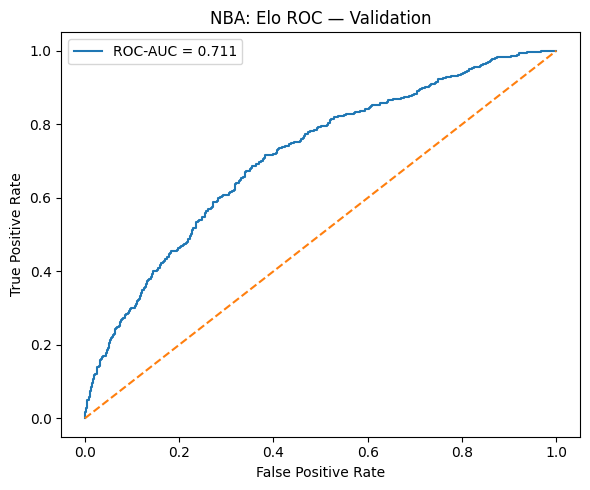

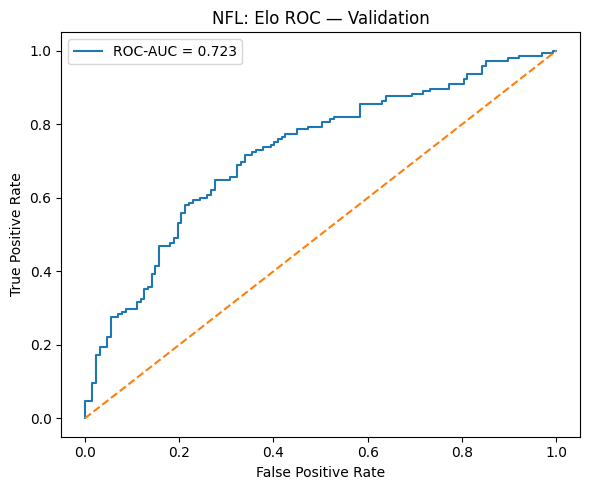

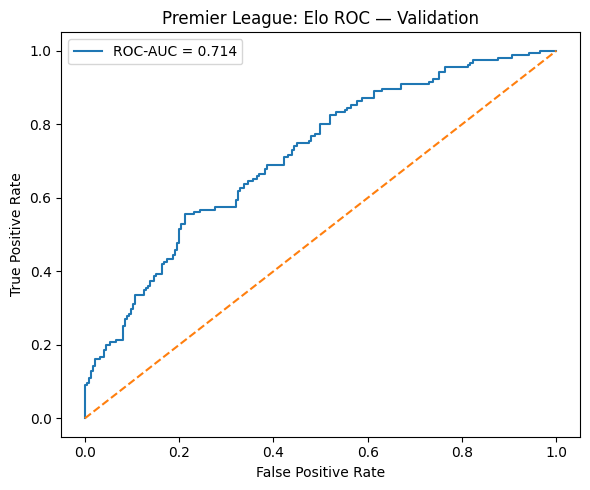


Elo validation metrics:


,sport,model,data_split,games,accuracy,precision,recall,f1,roc_auc,brier_score,log_loss,true_negative,false_positive,false_negative,true_positive
0,NBA,Elo,VALIDATION,1225,0.658776,0.701131,0.650675,0.674961,0.710962,0.217111,0.623030,373,185,233,434
1,NFL,Elo,VALIDATION,272,0.676471,0.717557,0.648276,0.681159,0.722780,0.216059,0.622503,90,37,51,94
2,Premier League,Elo,VALIDATION,380,0.639474,0.547872,0.664516,0.600583,0.713864,0.216701,0.620839,140,85,52,103


✅ Saved: /content/againstallodds/results/week8_nba_elo_history.csv
✅ Saved: /content/againstallodds/results/week8_nfl_elo_history.csv
✅ Saved: /content/againstallodds/results/week8_premier_league_elo_history.csv

Logistic Regression vs Elo:


,sport,model,games,accuracy,precision,recall,f1,roc_auc,brier_score,log_loss
0,NBA,Logistic Regression,1209,0.663358,0.673469,0.747734,0.708661,0.720033,0.211450,0.609445
3,NBA,Elo,1225,0.658776,0.701131,0.650675,0.674961,0.710962,0.217111,0.623030
4,NFL,Elo,272,0.676471,0.717557,0.648276,0.681159,0.722780,0.216059,0.622503
1,NFL,Logistic Regression,256,0.640625,0.643836,0.701493,0.671429,0.701676,0.219972,0.629782
5,Premier League,Elo,380,0.639474,0.547872,0.664516,0.600583,0.713864,0.216701,0.620839
2,Premier League,Logistic Regression,370,0.651351,0.569620,0.596026,0.582524,0.704225,0.215326,0.616042


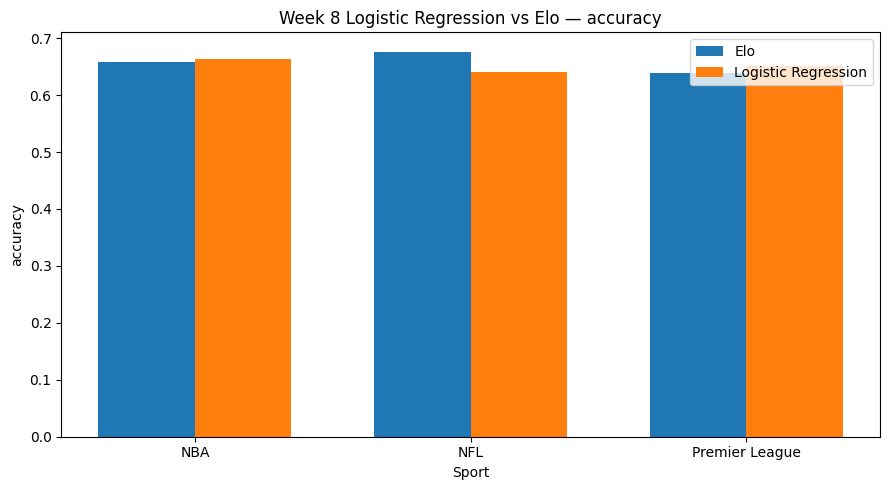

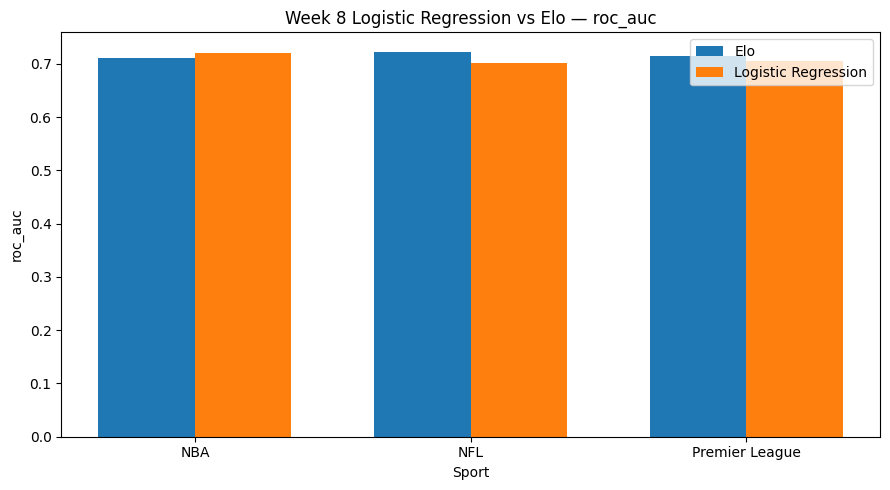

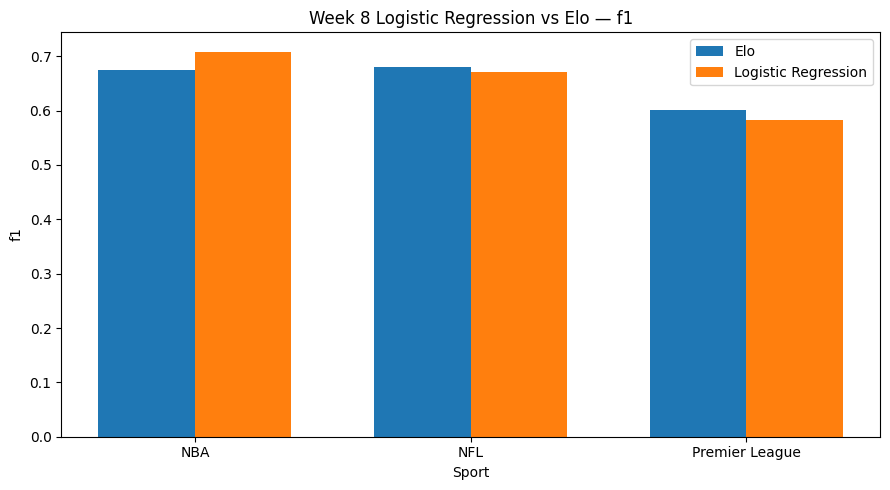

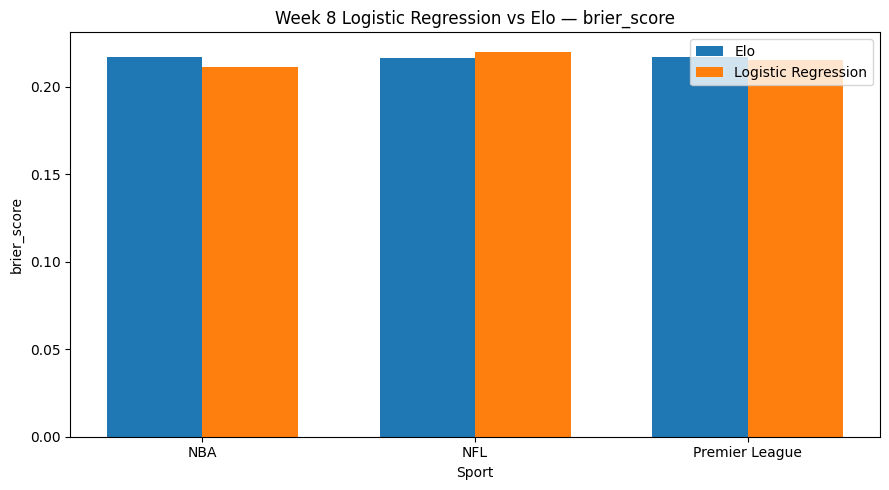

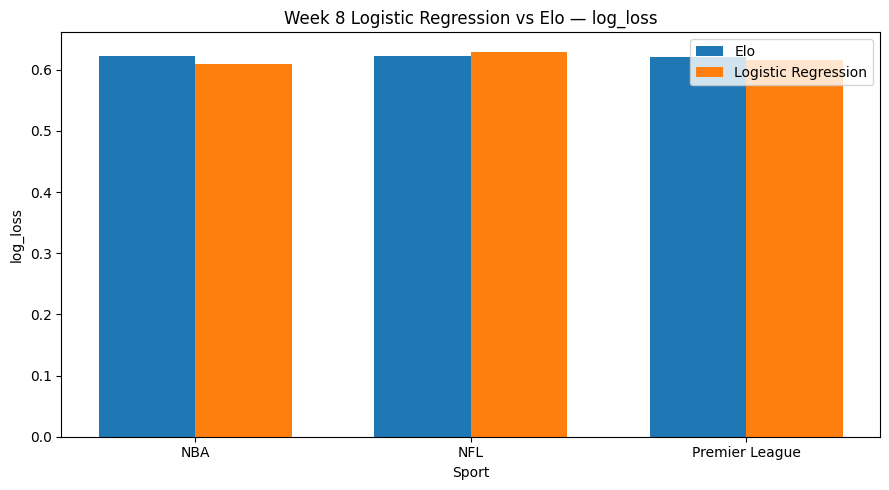

,check,passed
0,three_sports_have_elo,True
1,three_validation_elo_metrics,True
2,elo_probabilities_between_0_and_1,True
3,logistic_metrics_available,True
4,comparison_created,True
5,test_held_out_by_default,True
6,documentation_created,True



AGAINST ALL ODDS — WEEK 8 COMPLETE
✅ Logistic Regression: NBA, NFL, Premier League
✅ Coefficients, odds ratios, significance, probabilities
✅ Elo rebuilt chronologically
✅ Elo compared against Logistic Regression
✅ TEST split held out
✅ Week 8 results, documentation, and figures saved
✅ GitHub upload ZIP created:
/content/againstallodds/Against_All_Odds_Week8_GitHub_Upload.zip

Next project stage:
Week 9 — Gradient Boosting and Model Comparison

To download the Week 8 GitHub ZIP, run:
from google.colab import files
files.download(str(WEEK8_ZIP))


In [3]:

# ============================================================
# AGAINST ALL ODDS — WEEK 8B: ELO MODEL
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import sys
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    brier_score_loss,
    log_loss,
    roc_curve,
)

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_TITLE = "Against All Odds"
WEEK_NUMBER = 8

ELO_INITIAL = 1500.0
ELO_K = 20.0

# Keep final TEST data untouched during Week 8.
USE_TEST_SPLIT = False

CLEAN_INPUTS = {
    "NBA": "nba_games_clean_2021_22_to_2025_26.csv",
    "NFL": "nfl_games_clean_2021_to_2025.csv",
    "Premier League": "premier_league_games_clean_2021_22_to_2025_26.csv",
}


def running_in_colab():
    return "google.colab" in sys.modules


def choose_project_root():
    cwd = Path.cwd().resolve()

    candidates = [
        cwd if cwd.name.lower().replace("_", "-") in {
            "againstallodds",
            "against-all-odds",
        } else None,
        Path("/content/againstallodds"),
        Path("/content/Against-All-Odds"),
        Path("/content/drive/MyDrive/againstallodds"),
        Path("/content/drive/MyDrive/Against-All-Odds"),
    ]

    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return candidate

    if running_in_colab():
        return Path("/content/againstallodds")

    return cwd / "againstallodds"


PROJECT_ROOT = choose_project_root()
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures" / "week8"
DOCS_DIR = PROJECT_ROOT / "docs"

for folder in [
    CLEAN_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    DOCS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"✅ {PROJECT_TITLE} — Week {WEEK_NUMBER}: Elo Model")
print("Project root:", PROJECT_ROOT)


def search_locations():
    locations = [
        PROJECT_ROOT,
        CLEAN_DIR,
        Path("/content"),
        Path("/content/week8_elo_inputs"),
        Path.cwd().resolve(),
    ]

    for extra in [
        Path("/content/drive/MyDrive/againstallodds"),
        Path("/content/drive/MyDrive/Against-All-Odds"),
    ]:
        if extra.exists():
            locations.append(extra)

    return list(dict.fromkeys([p for p in locations if p.exists()]))


def find_exact_file(filename):
    for root in search_locations():
        direct = root / filename
        if direct.exists():
            return direct

    for root in search_locations():
        try:
            matches = list(root.rglob(filename))
        except (PermissionError, OSError):
            matches = []

        if matches:
            return matches[0]

    return None


def resolve_clean_inputs():
    found = {
        sport: find_exact_file(filename)
        for sport, filename in CLEAN_INPUTS.items()
    }

    missing = [
        filename
        for sport, filename in CLEAN_INPUTS.items()
        if found[sport] is None
    ]

    if missing and running_in_colab():
        print("\nMissing clean game-level CSVs:")
        for name in missing:
            print(" -", name)

        print("\nUpload the missing files or a ZIP containing them.")

        from google.colab import files

        uploaded = files.upload()
        upload_dir = Path("/content/week8_elo_inputs")
        upload_dir.mkdir(parents=True, exist_ok=True)

        for name, blob in uploaded.items():
            destination = upload_dir / Path(name).name
            destination.write_bytes(blob)

            if zipfile.is_zipfile(destination):
                with zipfile.ZipFile(destination, "r") as archive:
                    archive.extractall(upload_dir)

        found = {
            sport: find_exact_file(filename)
            for sport, filename in CLEAN_INPUTS.items()
        }

    still_missing = [
        CLEAN_INPUTS[sport]
        for sport, path in found.items()
        if path is None
    ]

    if still_missing:
        raise FileNotFoundError(
            "Week 8 Elo cannot start because these clean game-level files are missing:\n"
            + "\n".join(f" - {name}" for name in still_missing)
            + "\n\nUpload the Weeks 3–5 clean game CSVs."
        )

    return found


INPUT_PATHS = resolve_clean_inputs()

print("\n✅ Elo inputs located:")
for sport, path in INPUT_PATHS.items():
    print(f" - {sport}: {path}")


# ============================================================
# LOAD AND STANDARDIZE GAME OUTCOMES
# ============================================================

nba = pd.read_csv(
    INPUT_PATHS["NBA"],
    dtype={"game_id": "string"},
    parse_dates=["game_date"],
)

nfl = pd.read_csv(
    INPUT_PATHS["NFL"],
    dtype={"game_id": "string"},
    parse_dates=["game_date"],
)

epl = pd.read_csv(
    INPUT_PATHS["Premier League"],
    dtype={"game_id": "string"},
    parse_dates=["game_date"],
)


def prepare_nba(df):
    required = [
        "game_id",
        "game_date",
        "data_split",
        "home_team_abbr",
        "away_team_abbr",
        "HOME_WIN",
    ]

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"NBA missing columns: {missing}"
        )

    out = df[required].copy()

    out = out.rename(
        columns={
            "home_team_abbr": "home_team",
            "away_team_abbr": "away_team",
        }
    )

    out["actual_home"] = pd.to_numeric(
        out["HOME_WIN"],
        errors="coerce",
    )

    out["binary_HOME_WIN"] = out[
        "actual_home"
    ]

    return out


def prepare_nfl(df):
    required = [
        "game_id",
        "game_date",
        "data_split",
        "home_team",
        "away_team",
        "home_score",
        "away_score",
    ]

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"NFL missing columns: {missing}"
        )

    out = df[required].copy()

    home_score = pd.to_numeric(
        out["home_score"],
        errors="coerce",
    )

    away_score = pd.to_numeric(
        out["away_score"],
        errors="coerce",
    )

    out["actual_home"] = np.select(
        [
            home_score.gt(away_score),
            home_score.lt(away_score),
        ],
        [1.0, 0.0],
        default=0.5,
    )

    # Binary target excludes ties.
    out["binary_HOME_WIN"] = np.select(
        [
            home_score.gt(away_score),
            home_score.lt(away_score),
        ],
        [1.0, 0.0],
        default=np.nan,
    )

    return out


def prepare_epl(df):
    required = [
        "game_id",
        "game_date",
        "data_split",
        "home_team",
        "away_team",
        "home_goals",
        "away_goals",
    ]

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Premier League missing columns: {missing}"
        )

    out = df[required].copy()

    home_goals = pd.to_numeric(
        out["home_goals"],
        errors="coerce",
    )

    away_goals = pd.to_numeric(
        out["away_goals"],
        errors="coerce",
    )

    # Elo update:
    # home win = 1, draw = 0.5, away win = 0.
    out["actual_home"] = np.select(
        [
            home_goals.gt(away_goals),
            home_goals.lt(away_goals),
        ],
        [1.0, 0.0],
        default=0.5,
    )

    # Project binary target:
    # home win = 1, draw/away win = 0.
    out["binary_HOME_WIN"] = (
        home_goals.gt(away_goals)
    ).astype(float)

    return out


elo_data = {
    "NBA": prepare_nba(nba),
    "NFL": prepare_nfl(nfl),
    "Premier League": prepare_epl(epl),
}

for sport, df in elo_data.items():
    df["data_split"] = (
        df["data_split"]
        .astype("string")
        .str.upper()
        .str.strip()
    )

    df.sort_values(
        ["game_date", "game_id"],
        inplace=True,
        kind="stable",
    )

    df.reset_index(
        drop=True,
        inplace=True,
    )

    print(
        sport,
        "| games =", len(df),
        "| splits =", sorted(df["data_split"].unique().tolist()),
    )


# ============================================================
# BUILD/UPDATE ELO CHRONOLOGICALLY
# ============================================================

def elo_expected(
    home_rating,
    away_rating,
):
    return 1.0 / (
        1.0
        + 10.0 ** (
            (away_rating - home_rating)
            / 400.0
        )
    )


def build_elo_history(df):
    out = (
        df
        .copy()
        .sort_values(
            ["game_date", "game_id"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    ratings = {}

    home_pre = []
    away_pre = []
    probabilities = []

    for row in out.itertuples(index=False):
        home_team = row.home_team
        away_team = row.away_team
        actual_home = float(
            row.actual_home
        )

        home_rating = ratings.get(
            home_team,
            ELO_INITIAL,
        )

        away_rating = ratings.get(
            away_team,
            ELO_INITIAL,
        )

        probability_home = elo_expected(
            home_rating,
            away_rating,
        )

        # Save pre-game values BEFORE update.
        home_pre.append(
            home_rating
        )

        away_pre.append(
            away_rating
        )

        probabilities.append(
            probability_home
        )

        # Update only after outcome is observed.
        ratings[home_team] = (
            home_rating
            + ELO_K
            * (
                actual_home
                - probability_home
            )
        )

        ratings[away_team] = (
            away_rating
            + ELO_K
            * (
                (1.0 - actual_home)
                - (1.0 - probability_home)
            )
        )

    out[
        "HOME_ELO_PRE"
    ] = home_pre

    out[
        "AWAY_ELO_PRE"
    ] = away_pre

    out[
        "ELO_DIFF"
    ] = (
        out["HOME_ELO_PRE"]
        - out["AWAY_ELO_PRE"]
    )

    out[
        "ELO_HOME_WIN_PROB"
    ] = probabilities

    out[
        "ELO_PREDICTION"
    ] = (
        out[
            "ELO_HOME_WIN_PROB"
        ]
        >= 0.50
    ).astype("int8")

    return out


elo_predictions = {
    sport: build_elo_history(df)
    for sport, df in elo_data.items()
}

for sport, df in elo_predictions.items():
    print(
        f"✅ {sport}: chronological Elo complete"
    )
    display(df.head())


# ============================================================
# EVALUATION HELPERS
# ============================================================

def evaluate_probabilities(
    y_true,
    probability,
):
    probability = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        1e-6,
        1 - 1e-6,
    )

    prediction = (
        probability >= 0.50
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1],
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            prediction,
        ),
        "precision": precision_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probability,
        ),
        "brier_score": brier_score_loss(
            y_true,
            probability,
        ),
        "log_loss": log_loss(
            y_true,
            probability,
            labels=[0, 1],
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }


def save_elo_roc(
    y_true,
    probability,
    sport,
):
    fpr, tpr, _ = roc_curve(
        y_true,
        probability,
    )

    auc_value = roc_auc_score(
        y_true,
        probability,
    )

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    ax.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {auc_value:.3f}",
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
    )

    ax.set_xlabel(
        "False Positive Rate"
    )

    ax.set_ylabel(
        "True Positive Rate"
    )

    ax.set_title(
        f"{sport}: Elo ROC — Validation"
    )

    ax.legend()
    fig.tight_layout()

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        FIGURES_DIR
        / f"week8_{safe_sport}_elo_roc_validation.png"
    )

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    return path


# ============================================================
# EVALUATE ELO ON VALIDATION
# ============================================================

elo_metric_rows = []
elo_prediction_paths = []
elo_figure_paths = []

for sport, df in elo_predictions.items():
    validation = df[
        df[
            "data_split"
        ].eq("VALIDATION")
    ].copy()

    validation = validation.dropna(
        subset=[
            "binary_HOME_WIN",
            "ELO_HOME_WIN_PROB",
        ]
    )

    if validation.empty:
        raise ValueError(
            f"{sport}: VALIDATION data are empty."
        )

    y_true = (
        validation[
            "binary_HOME_WIN"
        ]
        .astype(int)
    )

    probability = validation[
        "ELO_HOME_WIN_PROB"
    ]

    metrics = evaluate_probabilities(
        y_true,
        probability,
    )

    elo_metric_rows.append({
        "sport": sport,
        "model": "Elo",
        "data_split": "VALIDATION",
        "games": int(len(validation)),
        **metrics,
    })

    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        RESULTS_DIR
        / f"week8_{safe_sport}_elo_validation_predictions.csv"
    )

    validation[
        [
            "game_id",
            "game_date",
            "data_split",
            "home_team",
            "away_team",
            "binary_HOME_WIN",
            "HOME_ELO_PRE",
            "AWAY_ELO_PRE",
            "ELO_DIFF",
            "ELO_HOME_WIN_PROB",
            "ELO_PREDICTION",
        ]
    ].to_csv(
        path,
        index=False,
    )

    elo_prediction_paths.append(
        path
    )

    elo_figure_paths.append(
        save_elo_roc(
            y_true,
            probability,
            sport,
        )
    )

    if USE_TEST_SPLIT:
        test = df[
            df[
                "data_split"
            ].eq("TEST")
        ].dropna(
            subset=[
                "binary_HOME_WIN",
                "ELO_HOME_WIN_PROB",
            ]
        )

        if not test.empty:
            test_metrics = evaluate_probabilities(
                test[
                    "binary_HOME_WIN"
                ].astype(int),
                test[
                    "ELO_HOME_WIN_PROB"
                ],
            )

            elo_metric_rows.append({
                "sport": sport,
                "model": "Elo",
                "data_split": "TEST",
                "games": int(len(test)),
                **test_metrics,
            })


elo_metrics = pd.DataFrame(
    elo_metric_rows
)

ELO_METRICS_PATH = (
    RESULTS_DIR
    / "week8_elo_metrics.csv"
)

elo_metrics.to_csv(
    ELO_METRICS_PATH,
    index=False,
)

print("\nElo validation metrics:")
display(elo_metrics)


# ============================================================
# SAVE FULL CHRONOLOGICAL ELO HISTORY
# ============================================================

elo_history_paths = []

for sport, df in elo_predictions.items():
    safe_sport = (
        sport.lower()
        .replace(" ", "_")
    )

    path = (
        RESULTS_DIR
        / f"week8_{safe_sport}_elo_history.csv"
    )

    df.to_csv(
        path,
        index=False,
    )

    elo_history_paths.append(
        path
    )

    print("✅ Saved:", path)


# ============================================================
# COMPARE ELO AGAINST LOGISTIC REGRESSION
# ============================================================

LOGISTIC_METRICS_PATH = (
    RESULTS_DIR
    / "week8_logistic_regression_metrics.csv"
)

if not LOGISTIC_METRICS_PATH.exists():
    raise FileNotFoundError(
        "Run 09_logistic_regression.ipynb first. "
        "week8_logistic_regression_metrics.csv is missing."
    )

logistic_metrics = pd.read_csv(
    LOGISTIC_METRICS_PATH
)

logistic_validation = logistic_metrics[
    logistic_metrics[
        "data_split"
    ].eq("VALIDATION")
].copy()

elo_validation = elo_metrics[
    elo_metrics[
        "data_split"
    ].eq("VALIDATION")
].copy()

comparison = pd.concat(
    [
        logistic_validation,
        elo_validation,
    ],
    ignore_index=True,
)

COMPARISON_PATH = (
    RESULTS_DIR
    / "week8_logistic_vs_elo_comparison.csv"
)

comparison.to_csv(
    COMPARISON_PATH,
    index=False,
)

print("\nLogistic Regression vs Elo:")
display(
    comparison[
        [
            "sport",
            "model",
            "games",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "brier_score",
            "log_loss",
        ]
    ].sort_values(
        ["sport", "roc_auc"],
        ascending=[
            True,
            False,
        ],
    )
)


# ============================================================
# MODEL-COMPARISON FIGURES
# ============================================================

comparison_figure_paths = []

for metric in [
    "accuracy",
    "roc_auc",
    "f1",
    "brier_score",
    "log_loss",
]:
    pivot = (
        comparison
        .pivot(
            index="sport",
            columns="model",
            values=metric,
        )
        .reindex(
            [
                "NBA",
                "NFL",
                "Premier League",
            ]
        )
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    x = np.arange(
        len(pivot.index)
    )

    width = 0.35

    models = list(
        pivot.columns
    )

    for i, model_name in enumerate(models):
        offset = (
            i
            - (
                len(models) - 1
            ) / 2
        ) * width

        ax.bar(
            x + offset,
            pivot[
                model_name
            ].values,
            width=width,
            label=model_name,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        pivot.index
    )

    ax.set_xlabel("Sport")
    ax.set_ylabel(metric)
    ax.set_title(
        f"Week 8 Logistic Regression vs Elo — {metric}"
    )
    ax.legend()

    fig.tight_layout()

    path = (
        FIGURES_DIR
        / f"week8_logistic_vs_elo_{metric}.png"
    )

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    comparison_figure_paths.append(
        path
    )


# ============================================================
# DOCUMENTATION
# ============================================================

doc_text = f"""# Against All Odds — Week 8 Logistic Regression and Elo

Generated: {datetime.now(timezone.utc).isoformat(timespec="seconds")}

Week 8 built the project's first serious predictive models.

Separate logistic-regression models were trained for the NBA, NFL, and Premier
League. Logistic regression was interpreted using coefficients, odds ratios,
statistical significance, and predicted probabilities.

Elo ratings were rebuilt chronologically. For each game, the pre-game ratings
and Elo probability were stored before the current result was used to update
the ratings.

NFL ties and Premier League draws contribute 0.5 to the Elo update.

Logistic regression and Elo were compared on VALIDATION using accuracy,
precision, recall, F1, ROC-AUC, Brier score, and log loss.

TEST remained held out by default.
"""

WEEK8_DOC_PATH = (
    DOCS_DIR
    / "week8_logistic_regression_and_elo.md"
)

WEEK8_DOC_PATH.write_text(
    doc_text,
    encoding="utf-8",
)

readme_addition = """## Week 8 — Logistic Regression and Elo

Built the first serious predictive models for the NBA, NFL, and Premier League.
Separate logistic-regression models were trained and interpreted using
coefficients, odds ratios, statistical significance, and predicted
probabilities. Chronological Elo ratings were also rebuilt and evaluated.
Logistic regression and Elo were compared on the validation split while the
final test split remained held out.
"""

WEEK8_README_PATH = (
    DOCS_DIR
    / "week8_README_addition.md"
)

WEEK8_README_PATH.write_text(
    readme_addition,
    encoding="utf-8",
)


# ============================================================
# QUALITY CHECKS
# ============================================================

quality_checks = {
    "three_sports_have_elo": (
        set(
            elo_predictions.keys()
        )
        == {
            "NBA",
            "NFL",
            "Premier League",
        }
    ),
    "three_validation_elo_metrics": (
        len(
            elo_metrics[
                elo_metrics[
                    "data_split"
                ].eq("VALIDATION")
            ]
        )
        == 3
    ),
    "elo_probabilities_between_0_and_1": all(
        df[
            "ELO_HOME_WIN_PROB"
        ].between(
            0,
            1,
        ).all()
        for df in elo_predictions.values()
    ),
    "logistic_metrics_available": (
        LOGISTIC_METRICS_PATH.exists()
    ),
    "comparison_created": (
        COMPARISON_PATH.exists()
    ),
    "test_held_out_by_default": (
        USE_TEST_SPLIT is False
    ),
    "documentation_created": (
        WEEK8_DOC_PATH.exists()
        and WEEK8_README_PATH.exists()
    ),
}

week8_quality = pd.DataFrame([
    {
        "check": name,
        "passed": bool(value),
    }
    for name, value in quality_checks.items()
])

WEEK8_QUALITY_PATH = (
    RESULTS_DIR
    / "week8_quality_report.csv"
)

week8_quality.to_csv(
    WEEK8_QUALITY_PATH,
    index=False,
)

display(
    week8_quality
)

if not week8_quality[
    "passed"
].all():
    raise RuntimeError(
        "Week 8 quality checks failed."
    )


# ============================================================
# PACKAGE WEEK 8 RUNTIME OUTPUTS FOR GITHUB
# ============================================================

WEEK8_ZIP = (
    PROJECT_ROOT
    / "Against_All_Odds_Week8_GitHub_Upload.zip"
)

if WEEK8_ZIP.exists():
    WEEK8_ZIP.unlink()

runtime_files = []

runtime_files.extend(
    RESULTS_DIR.glob(
        "week8_*"
    )
)

runtime_files.extend(
    FIGURES_DIR.glob(
        "week8_*.png"
    )
)

runtime_files.extend([
    WEEK8_DOC_PATH,
    WEEK8_README_PATH,
])

runtime_files = list(
    dict.fromkeys(
        path
        for path in runtime_files
        if path.exists()
    )
)

with zipfile.ZipFile(
    WEEK8_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for path in runtime_files:
        archive.write(
            path,
            path.relative_to(
                PROJECT_ROOT
            ),
        )

    push_list = """AGAINST ALL ODDS — WEEK 8 GITHUB PUSH LIST

notebooks/
  09_logistic_regression.ipynb
  10_elo_model.ipynb

docs/
  week8_logistic_regression_notes.md
  week8_logistic_regression_and_elo.md
  week8_README_addition.md

results/
  week8_logistic_regression_metrics.csv
  week8_logistic_regression_coefficients.csv
  week8_logistic_significant_features.csv
  week8_logistic_quality_report.csv
  week8_*_logistic_validation_predictions.csv
  week8_*_logistic_statsmodels_summary.txt
  week8_elo_metrics.csv
  week8_*_elo_validation_predictions.csv
  week8_*_elo_history.csv
  week8_logistic_vs_elo_comparison.csv
  week8_quality_report.csv

figures/week8/
  Upload all generated Week 8 PNG files.

Also update README.md using docs/week8_README_addition.md.
"""

    push_path = (
        PROJECT_ROOT
        / "WEEK8_GITHUB_PUSH_LIST.txt"
    )

    push_path.write_text(
        push_list,
        encoding="utf-8",
    )

    archive.write(
        push_path,
        arcname="WEEK8_GITHUB_PUSH_LIST.txt",
    )


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 78)
print("AGAINST ALL ODDS — WEEK 8 COMPLETE")
print("=" * 78)

print("✅ Logistic Regression: NBA, NFL, Premier League")
print("✅ Coefficients, odds ratios, significance, probabilities")
print("✅ Elo rebuilt chronologically")
print("✅ Elo compared against Logistic Regression")
print("✅ TEST split held out")
print("✅ Week 8 results, documentation, and figures saved")
print("✅ GitHub upload ZIP created:")
print(WEEK8_ZIP)

print("\nNext project stage:")
print("Week 9 — Gradient Boosting and Model Comparison")

if running_in_colab():
    print(
        "\nTo download the Week 8 GitHub ZIP, run:"
    )
    print("from google.colab import files")
    print("files.download(str(WEEK8_ZIP))")


In [4]:
from google.colab import files
files.download(str(WEEK8_ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***In Week 8, work centered on developing initial predictive models for the NBA, NFL, and Premier League within the Against All Odds project. Individual logistic regression models were constructed for every league, with results analyzed through coefficients, odds ratios, p-values, and home victory probabilities to fulfill capstone requirements. Time-aware Elo ratings were implemented to ensure team scores were adjusted exclusively post-match, avoiding future data contamination. Finally, model performance across logistic regression and Elo frameworks was assessed using metrics like accuracy, F1 score, ROC-AUC, Brier score, and log loss, keeping test datasets isolated for upcoming reviews.***